___
# FIGURE 3BCD *Plot* inpatient pain decoding
Shirvalkar et al., Nature Medicine 2026

This notebook summarizes:
- cohort-level Lasso performance (Figure 3B, ground truth vs predicted pain scores)
- cohort-level LDA performance (Figure 3C, true positive rate vs false positive rate)
- P3 feature prominence in brain regions across pain decoding models. (Figure 3D)

Inputs:
- main_dir: directory of repository so files can be loaded/saved
  
Outputs (Figure 3 subpanels made):
- Figure 3B: scatter plot of ground truth vs predicted pain scores across all participants
- Figure 3C: ROC for linear discriminant analysis of predicted pain across all participants
- Figure 3D: Side-by-side bar plot of left/right hemisphere regions
  _________

### Repository root (resolved automatically; set `NATMED_REPO` to override)

In [18]:
import os
# Repository root: defaults to the parent of python_code/, i.e. this notebook's
# grandparent folder. Override by setting the NATMED_REPO environment variable
# or replacing this line with an explicit path to your local copy.
main_dir = os.environ.get('NATMED_REPO',
    os.path.abspath(os.path.join(os.getcwd(), os.pardir))) + '/'


### Figures 3B & 3C configuration
For cohort-level LASSO and LDA pain decoding plots, SET which pain metric and time window is used.

Shirvalkar et al., 2026 uses the highest r-squared and AUC, respectively, unless there were fewer than 10 surveys used.

In [19]:
model_config = {
    'P1': {'LASSO': ('nrs_s0', 'five_minute'),
           'LDA'  : ('nrs_s0', 'five_minute')},

    'P2': {'LASSO': ('unpleasantness_vas_s0', 'one_minute'),
           'LDA'  : ('relief_s0', 'five_minute')},

    'P3': {'LASSO': ('intensity_vas_s0', 'thirty_minute'),
           'LDA'  : ('intensity_vas_s0', 'five_minute')},

    'P4': {'LASSO': ('nrs_s0', 'ten_minute'),
           'LDA'  : ('unpleasantness_vas_s0', 'thirty_minute')},

    'P5': {'LASSO': ('intensity_vas_s0', 'ten_minute'),
           'LDA'  : ('intensity_vas_s0', 'ten_minute')}
}

### Figure 3D configuration — set which participant(s) are plotted 

In [20]:
### all pt_labels shown in comment below
# pt_labels     = ['P1'   ,    'P2',    'P3',    'P4',   'P5'] #
pt_labels     = ['P3']

In [21]:
# import modules
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
sys.path.append(str(Path(main_dir) / 'python_code/shared_utilities'))
from utility.figure3_inpatient_decoding_helpers import (split_by_hemisphere, create_hemisphere_plot, plot_lasso_scatter, plot_lda_roc)

In [22]:
# infer where data are saved and figures will be saved from main_dir
data_dir = Path(main_dir) / 'data/'
fig_dir  = Path(main_dir) / 'figures'

### Figure 3B, cohort-level Lasso performance

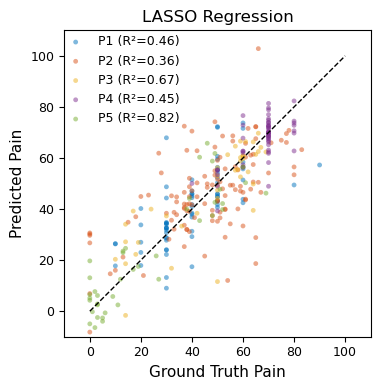

In [23]:
plot_lasso_scatter(model_config, data_dir, fig_dir, save_fig=True)

### Figure 3C, cohort-level LDA performance

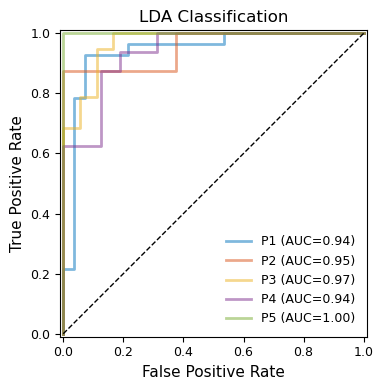

In [24]:
plot_lda_roc(model_config, data_dir, fig_dir, save_fig=True)

### Figure 3D, Plot example (P3) feature counts by hemisphere

Plotting P3 feature prominence
    Left hemisphere: 10 regions
    Right hemisphere: 10 regions
    Saved: <repo>

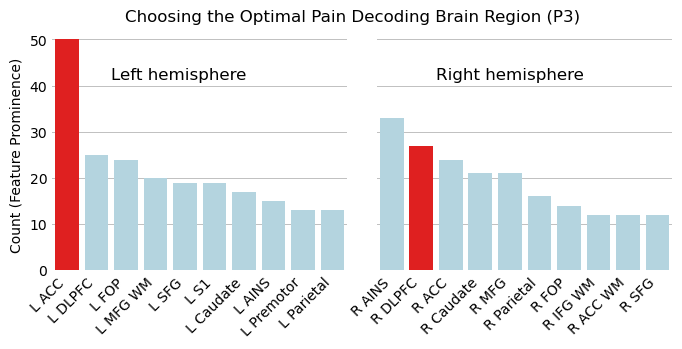

In [24]:
# specify which regions to set to red
mapping = {
    'P1': ([1], [2]),
    'P2': ([0], [0]),
    'P3': ([0], [1]),
    'P4': (None, None),
    'P5': (None, None),
}
# plot all specified participants
for pt in pt_labels:
    print(f"Plotting {pt} feature prominence")

    # P3 is the participant shown in Figure 3D, so its panel is saved to file.
    save_fig = (pt == 'P3')
    features_path = Path(data_dir) / 'figure3_processed_inpatient_pain_decoding' / f"{pt}_inpatient_feature_counts.xlsx"
    
    # Load feature counts data
    feature_counts = pd.read_excel(features_path)
    # Split by hemisphere
    left_df, right_df = split_by_hemisphere(feature_counts,TOP_N_REGIONS=10)
    # set certain regions to red based on final implant site
    ind_left, ind_right = mapping.get(pt, (None, None))
    # plot seperate hemispheres, but rank feature counts WITHIN hemisphere
    create_hemisphere_plot(left_df, right_df, pt, 
                           fig_dir/ 'Figure3D.pdf',
                           left_red_bars=ind_left,
                           right_red_bars=ind_right,
                           save_fig = save_fig)